# EDA отзывов Кинопоиска

Смотрим распределение тональности, пропуски, повторы и длину отзывов в исходных разбиениях.

### Объединяем отызывы из трёх разбиений в одну таблицу reviews

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
data = root / "data" / "kinopoisk"
splits = ["train", "validation", "test"]
classes = ["Bad", "Neutral", "Good"]

reviews = pd.concat(
    [pd.read_json(data / f"{split}.jsonl", lines=True, dtype={"id": str}).assign(split=split)
     for split in splits],
    ignore_index=True
)
reviews[["split", "id", "label", "label_text"]].head()

,split,id,label,label_text
0,train,0,2,Good
1,train,1,0,Bad
2,train,2,1,Neutral
3,train,3,0,Bad
4,train,4,2,Good


## Размеры разбиений и распределение классов

In [7]:
counts = pd.crosstab(reviews["split"], reviews["label_text"]).reindex(splits)[classes]
counts.assign(total=counts.sum(axis=1))

label_text,Bad,Neutral,Good,total
split,,,,
train,3500,3500,3500,10500
validation,500,500,500,1500
test,500,500,500,1500


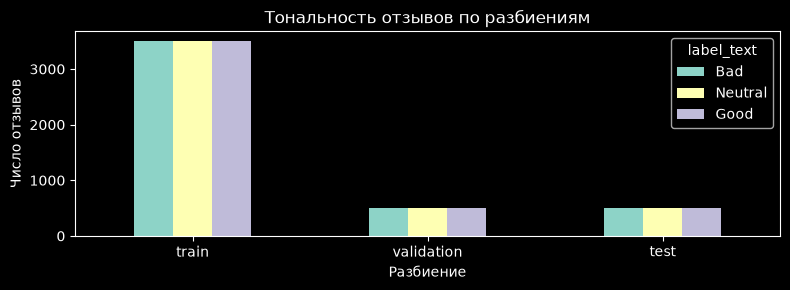

In [8]:
counts.plot.bar(rot=0, figsize=(8, 3))
plt.title("Тональность отзывов по разбиениям")
plt.xlabel("Разбиение")
plt.ylabel("Число отзывов")
plt.tight_layout()
plt.show()

 В датасете 13500 отзывов. В обучающей выборке 10500 отзывов, по 3500 на каждый класс. В валидационной и тестовой выборках по 1500 отзывов, по 500 на класс. Во всех трёх разбиениях на каждый класс приходится треть отзывов, поэтому дисбаланса классов по числу примеров нет.

## Пропуски и повторы

Проверяем пропуски, считаем точные повторы и повторы после нормализации Unicode, регистра и пробелов. При сравнении разбиений считаем уникальные совпавшие тексты.

In [9]:
quality = reviews.isna().groupby(reviews["split"]).sum().reindex(splits)
quality["empty_text"] = reviews["text"].str.strip().eq("").groupby(reviews["split"]).sum()
quality["label_mismatch"] = (
    reviews["label"].map({0: "Bad", 1: "Neutral", 2: "Good"}).ne(reviews["label_text"])
    .groupby(reviews["split"]).sum()
)
quality

,id,text,label,label_text,split,empty_text,label_mismatch
split,,,,,,,
train,0,0,0,0,0,0,0
validation,0,0,0,0,0,0,0
test,0,0,0,0,0,0,0


In [10]:
texts = reviews.dropna(subset=["text"]).copy()
texts["normalized"] = (texts["text"].str.normalize("NFKC").str.casefold()
                       .str.replace(r"\s+", " ", regex=True).str.strip())

duplicates = pd.DataFrame({
    "exact": texts.duplicated(["split", "text"]).groupby(texts["split"]).sum(),
    "normalized": texts.duplicated(["split", "normalized"]).groupby(texts["split"]).sum()
}).reindex(splits)
duplicates

,exact,normalized
split,,
train,0,2
validation,0,0
test,0,0


In [11]:
by_split = texts.groupby("split")["normalized"].agg(set)
pd.Series({
    "train / validation": len(by_split["train"] & by_split["validation"]),
    "train / test": len(by_split["train"] & by_split["test"]),
    "validation / test": len(by_split["validation"] & by_split["test"])
}, name="Совпавшие тексты")

train / validation    0
train / test          0
validation / test     0
Name: Совпавшие тексты, dtype: int64

Во всех трёх разбиениях нет пропусков и пустых отзывов. Числовые и текстовые метки тональности совпадают во всех записях.

Точных повторов внутри разбиений нет. После нормализации в `train` обнаружены две повторные записи сверх первых экземпляров. В `validation` и `test` повторов не найдено.

Ни в одной паре разбиений нормализованные тексты не совпали. Проверка не выявила утечки данных через повторяющиеся отзывы.

## Длина отзывов

Измеряем длину в символах и словах. На графике показываем основной диапазон до 99-го перцентиля. Максимум по каждому классу остаётся виден в таблице.

In [12]:
texts["chars"] = texts["text"].str.len()
texts["words"] = texts["text"].str.split().str.len()
print("Медиана по всем отзывам:", round(texts["chars"].median()), "символов")
stats = texts.groupby("label_text")[["chars", "words"]].quantile([0, 0.5, 0.95, 0.99, 1])
stats.rename_axis(index=["Класс", "Перцентиль"]).round(1)

Медиана по всем отзывам: 1578 символов


chars   words
Класс   Перцентиль                 
Bad     0.00           33.0     5.0
        0.50         1675.5   256.0
        0.95         4721.3   717.0
        0.99         6398.2   978.0
        1.00         7703.0  1108.0
Good    0.00           62.0     8.0
        0.50         1579.0   242.0
        0.95         4578.3   698.0
        0.99         6424.2   971.0
        1.00        14759.0  2206.0
Neutral 0.00           69.0     9.0
        0.50         1467.5   222.0
        0.95         4533.3   670.1
        0.99         6436.1   969.0
        1.00        18363.0  2969.0

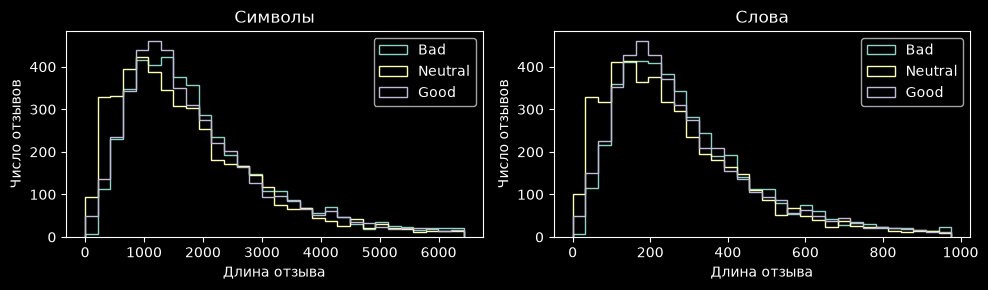

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for column, title, ax in zip(["chars", "words"], ["Символы", "Слова"], axes):
    limit = texts[column].quantile(0.99)
    for label in classes:
        lengths = texts.loc[texts["label_text"].eq(label), column]
        ax.hist(lengths, bins=30, range=(0, limit), histtype="step", label=label)
    ax.set(title=title, xlabel="Длина отзыва", ylabel="Число отзывов")
    ax.legend()
plt.tight_layout()
plt.show()

Медианная длина отзыва по всему датасету — около 1578 символов. Отрицательные отзывы немного длиннее по медиане (256 слов), чем положительные (242 слова) и нейтральные (222 слова). При этом распределения длин заметно перекрываются: отзывы похожей длины встречаются во всех трёх классах.

Примерно 99% отзывов каждого класса укладываются в 6,4 тыс. символов, а максимальная длина в датасете достигает 18363 символов. При выборе ограничения длины для модели важно проверить, сколько отзывов и какая часть их текста будут обрезаны.

## Выводы
- Датасет содержит 13500 отзывов. Отрицательные, нейтральные и положительные отзывы представлены поровну в каждом из трёх разбиений. Пропусков, пустых текстов и расхождений между числовыми и текстовыми метками не обнаружено.

- После нормализации текста в обучающей выборке обнаружены две повторные записи. Между обучающей, валидационной и тестовой выборками совпадений нормализованных текстов не найдено. Перед обучением можно удалить эти две повторные записи из `train`, сохранив исходное разбиение.

- Медианная длина отзыва составляет около 1578 символов. Распределения длин по классам заметно перекрываются, а отдельные отзывы достигают 18363 символов. При подготовке данных для модели стоит измерить длину в токенах и проверить, какая доля отзывов будет обрезана при выбранном ограничении.